In [2]:
from jcm.forcing import DEFAULT_CO2_VMR_PPMV

# Control value is 360.0 ppmv
c0 = DEFAULT_CO2_VMR_PPMV  # 360.0
multipliers = [0.5, 2.0, 4.0, 8.0]
co2_values = {m: c0 * m for m in multipliers}

In [3]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ==============================================================================
# 1. Helper to compute area-weighted global annual-mean TOA Net Flux (W m^-2)
# ==============================================================================
def get_annual_global_toa(ds, spinup_years=1):
    """
    Computes post-spinup annual-mean global-mean net TOA radiative flux (W m^-2),
    defined positive downward: R_TOA = net_shortwave_toa - olr (or direct net var).
    Adjust variable names below to match your saved JCM netCDF output.
    """
    ds_post = ds.isel(time=slice(12 * spinup_years, None))
    
    # If TOA net flux is saved directly (e.g., 'toa_net_flux' or 'rad_toa'):
    if "toa_net_flux" in ds_post:
        toa_net = ds_post["toa_net_flux"]
    else:
        # Otherwise compute as Net Incoming Shortwave at TOA minus Outgoing Longwave (OLR)
        # In SPEEDY: 'tsr' (top shortwave radiation, downward net) - 'olr' (upward longwave)
        toa_net = ds_post["tsr"] - ds_post["olr"]
        
    weights = np.cos(np.deg2rad(toa_net.lat))
    global_monthly = toa_net.weighted(weights).mean(dim=("lat", "lon"))
    
    # Coarsen 12 monthly means into annual means
    annual_means = global_monthly.coarsen(time=12, boundary="trim").mean()
    return annual_means.values

# ==============================================================================
# 2. Compute ERF and Standard Errors across 0.5x, 1x, 2x, 4x, 8x CO2
# ==============================================================================
# Replace ds_ctrl, ds_0p5x, ds_2x, ds_4x, ds_8x with your loaded xarray Datasets
experiments = {
    0.5: ds_0p5x,
    1.0: ds_ctrl,
    2.0: ds_2x,
    4.0: ds_4x,
    8.0: ds_8x,
}

toa_ctrl_ann = get_annual_global_toa(ds_ctrl, spinup_years=1)
n_ctrl = len(toa_ctrl_ann)
var_ctrl = np.var(toa_ctrl_ann, ddof=1)

ratios = np.array([0.5, 1.0, 2.0, 4.0, 8.0])
ln_ratios = np.log(ratios)
erf_vals = []
erf_ses = []

for r in ratios:
    if r == 1.0:
        erf_vals.append(0.0)
        erf_ses.append(0.0)
    else:
        toa_pert_ann = get_annual_global_toa(experiments[r], spinup_years=1)
        n_pert = len(toa_pert_ann)
        var_pert = np.var(toa_pert_ann, ddof=1)
        
        erf = np.mean(toa_pert_ann) - np.mean(toa_ctrl_ann)
        se = np.sqrt(var_pert / n_pert + var_ctrl / n_ctrl)
        erf_vals.append(erf)
        erf_ses.append(se)

erf_vals = np.array(erf_vals)
erf_ses = np.array(erf_ses)

# Print summary table for your report
for r, lnr, val, se in zip(ratios, ln_ratios, erf_vals, erf_ses):
    myhre_val = 5.35 * lnr
    print(f"{r:4.1f}x CO2 | ln(C/C0) = {lnr:+6.3f} | SPEEDY ERF = {val:+6.2f} ± {se:4.2f} W/m² | Myhre = {myhre_val:+6.2f} W/m²")

# ==============================================================================
# 3. Load ClimateBench NorESM2 ERF Data and Map Historical CO2 (1850-2014)
# ==============================================================================
noresm_df = pd.read_csv("inputs_NorESM2_ERF.csv")

# In CMIP6 / ClimateBench historical (1850-2014), NorESM2's 'CO2' ERF column
# follows a logarithmic trajectory from 0.0 W/m² (1850, 284.32 ppm) to 1.847 W/m² (2014, 397.55 ppm),
# giving an effective slope of 5.511 * ln(C/C0) W/m².
ln_c_2014 = np.log(397.55 / 284.32)  # 0.3352
noresm_slope = noresm_df["CO2"].iloc[-1] / ln_c_2014  # 5.5106 W m^-2
noresm_ln_c = noresm_df["CO2"] / noresm_slope

# ==============================================================================
# 4. Plot ERF vs ln(C/C0) and NorESM2 Historical ERF Time Series
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: ERF vs ln(C/C0)
x_grid = np.linspace(-0.85, 2.25, 200)
ax1.plot(x_grid, 5.35 * x_grid, "k--", lw=1.8, label=r"Myhre et al. (1998): $5.35\,\ln(C/C_0)$")
ax1.plot(x_grid, noresm_slope * x_grid, "g:", lw=1.8, label=rf"NorESM2 Implied Slope ($\approx {noresm_slope:.2f}\,\ln(C/C_0)$)")
ax1.scatter(noresm_ln_c, noresm_df["CO2"], color="seagreen", s=18, alpha=0.6, label="NorESM2 Historical $\mathrm{CO_2}$ ERF (1850–2014)")
ax1.errorbar(ln_ratios, erf_vals, yerr=erf_ses, fmt="o-", color="tab:red", lw=2, capsize=4, markersize=6, label="SPEEDY (JCM) Fixed-SST ERF")

for r, x, y in zip(ratios, ln_ratios, erf_vals):
    ax1.annotate(f"{r:g}×", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

ax1.axhline(0, color="gray", lw=0.8, ls=":")
ax1.axvline(0, color="gray", lw=0.8, ls=":")
ax1.set_xlabel(r"$\ln(C / C_0)$")
ax1.set_ylabel(r"Effective Radiative Forcing ($\mathrm{W\ m^{-2}}$)")
ax1.set_title(r"(a) ERF as a Function of $\ln(\mathrm{CO_2 / CO_{2,0}})$")
ax1.legend(loc="upper left", fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Panel B: ClimateBench NorESM2 ERF Time Series (1850-2014) for Context
ax2.plot(noresm_df["year"], noresm_df["TOT"], color="lightgray", lw=1.2, label="NorESM2 Total ERF (TOT)")
ax2.plot(noresm_df["year"], noresm_df["GHG"], color="tab:orange", lw=1.5, alpha=0.8, label="NorESM2 GHG ERF")
ax2.plot(noresm_df["year"], noresm_df["AER"], color="tab:blue", lw=1.5, alpha=0.8, label="NorESM2 Aerosol ERF")
ax2.plot(noresm_df["year"], noresm_df["CO2"], color="seagreen", lw=2.2, label="NorESM2 $\mathrm{CO_2}$ ERF")
ax2.set_xlabel("Year")
ax2.set_ylabel(r"ERF ($\mathrm{W\ m^{-2}}$)")
ax2.set_title("(b) ClimateBench NorESM2 Historical ERF (1850–2014)")
ax2.legend(loc="upper left", fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("task6_erf_comparison.png", dpi=300)
plt.show()

NameError: name 'ds_0p5x' is not defined

In [4]:
import inspect
from jcm.model import Model
from jcm.forcing import ForcingData, DEFAULT_CO2_VMR_PPMV

print("Default CO2 (ppmv):", DEFAULT_CO2_VMR_PPMV)
print("Model.run signature:", inspect.signature(Model.run))

Default CO2 (ppmv): 420.0
Model.run signature: (self, initial_state=None, forcing: jcm.forcing.ForcingData = None, save_interval=10.0, total_time=None, end_time=None, output_averages=False, snapshot_interval=None, snapshot_variables=(), initial_physics_state: Any = None, observer_t0_days=None, observer_xs=None, progress: bool = False) -> jcm.predictions.ModelPredictions


In [8]:
from pathlib import Path
import hydra
import jcm.runners as runners

config_dir = str(Path(runners.__file__).parent / "config")
with hydra.initialize_config_dir(version_base=None, config_dir=config_dir):
    cfg = hydra.compose(config_name="config", overrides=["+configuration=speedy-t31"])

# Build model and control forcing
model = runners.build_model(cfg)
forcing = runners.build_forcing(cfg, model.coords, dycore=model.dycore)

print("Control forcing.co2_vmr:", forcing.co2_vmr)
print("Has monthly_means method on ModelPredictions?:", hasattr(runners.ModelPredictions, "monthly_means"))

# Quick 10-day test run with output_averages=True to see exact xarray variable names
test_preds = model.run(forcing=forcing, save_interval=5.0, total_time=10.0, output_averages=True)
test_ds = test_preds.to_xarray()
print("xarray data_vars:", list(test_ds.data_vars))
print("xarray coords:", list(test_ds.coords))

forcing.ozone_file=auto on a sigma-vertical grid — the packaged and mirror ozone products are interpolated onto hybrid-level pressures and would be mapped level-for-level onto unrelated sigma levels. Falling back to the ANALYTIC ozone profile; supply an on-grid forcing.ozone_file (built for this vertical grid) for production radiation.


Control forcing.co2_vmr: 420.0
Has monthly_means method on ModelPredictions?: True
xarray data_vars: ['u_wind', 'v_wind', 'temperature', 'specific_humidity', 'geopotential', 'normalized_surface_pressure', 'condensation.precls', 'condensation.dtlsc', 'condensation.dqlsc', 'convection.se', 'convection.cbmf', 'convection.qdif', 'convection.precnv', 'humidity.rh', 'humidity.qsat', 'land_model.stl_lm', 'longwave_rad.dfabs', 'longwave_rad.ftop', 'mod_radcon.ablco2', 'mod_radcon.alb_l', 'mod_radcon.alb_s', 'mod_radcon.albsfc', 'mod_radcon.snowc', 'mod_radcon.tau2.0', 'mod_radcon.tau2.1', 'mod_radcon.tau2.2', 'mod_radcon.tau2.3', 'mod_radcon.emis2.0', 'mod_radcon.emis2.1', 'mod_radcon.emis2.2', 'mod_radcon.emis2.3', 'mod_radcon.st4a.0', 'mod_radcon.st4a.1', 'mod_radcon.stratc.0', 'mod_radcon.stratc.1', 'mod_radcon.flux.0', 'mod_radcon.flux.1', 'mod_radcon.flux.2', 'mod_radcon.flux.3', 'shortwave_rad.qcloud', 'shortwave_rad.fsol', 'shortwave_rad.rsds', 'shortwave_rad.rsns', 'shortwave_rad.ozone

In [10]:
import os, gc, time
from pathlib import Path
import hydra
import jax
import jax.numpy as jnp
import numpy as np
import xarray as xr
import jcm.runners as runners

print("JAX backend:", jax.default_backend(), "| Devices:", jax.devices())

# 1. Build speedy-t31 model and base forcing
config_dir = str(Path(runners.__file__).parent / "config")
with hydra.initialize_config_dir(version_base=None, config_dir=config_dir):
    cfg = hydra.compose(config_name="config", overrides=["+configuration=speedy-t31"])

model = runners.build_model(cfg)
base_forcing = runners.build_forcing(cfg, model.coords, dycore=model.dycore)
terrain = model.dycore.terrain
c0 = float(np.asarray(base_forcing.co2_vmr))  # 420.0 ppmv
print(f"Control CO2 (C0): {c0} ppmv")

# 2. Run settings: 1 yr spinup + 10 yrs analysis, saving annual means directly (save_interval = 365.0)
spinup_years = 1
analysis_years = 10
total_years = spinup_years + analysis_years
save_interval = 365.0          # 1 average per year -> 73x less GPU VRAM!
total_days = total_years * 365.0

# Keep only the variables needed for Tasks 6 & 7 so files are tiny (~2 MB) and on CPU
keep_vars = [
    "shortwave_rad.ftop",
    "longwave_rad.ftop",
    "mod_radcon.ablco2",
    "surface_flux.t0",
    "surface_flux.tskin",
    "land_model.stl_lm",
    "surface_exchange.precipitation",
    "condensation.precls",
    "convection.precnv",
]

multipliers = [0.5, 1.0, 2.0, 4.0, 8.0]
experiments = {}
os.makedirs("co2_runs", exist_ok=True)

for m in multipliers:
    nc_path = f"co2_runs/speedy_co2_{m}x_annual.nc"
    # Only load if the file exists AND isn't an empty/corrupted partial file from the OOM crash
    if os.path.exists(nc_path) and os.path.getsize(nc_path) > 10000:
        print(f"Loading existing {nc_path}...")
        experiments[m] = xr.open_dataset(nc_path)
        continue

    co2_val = c0 * m
    t0 = time.perf_counter()
    print(f"Running {m}x CO2 ({co2_val:.0f} ppmv) for {total_years} years...", end=" ", flush=True)
    
    forcing_m = base_forcing.copy(co2_vmr=jnp.asarray(co2_val, dtype=jnp.float32))
    preds_m = model.run(
        forcing=forcing_m,
        save_interval=save_interval,
        total_time=total_days,
        output_averages=True,
        progress=False,
    )
    
    # Subset to needed variables and immediately copy from GPU to CPU NumPy arrays
    ds_full = preds_m.to_xarray()
    avail_vars = [v for v in keep_vars if v in ds_full]
    ds_cpu = ds_full[avail_vars].copy(deep=False)
    for v in avail_vars:
        ds_cpu[v] = (ds_cpu[v].dims, np.asarray(jax.device_get(ds_cpu[v].data)), ds_cpu[v].attrs)
        
    ds_cpu.to_netcdf(nc_path)
    experiments[m] = ds_cpu
    
    # Free GPU buffers before the next run
    del preds_m, ds_full, forcing_m
    gc.collect()
    print(f"Done in {time.perf_counter() - t0:.1f}s! Saved {nc_path}")

ds_0p5x = experiments[0.5]
ds_ctrl = experiments[1.0]
ds_2x   = experiments[2.0]
ds_4x   = experiments[4.0]
ds_8x   = experiments[8.0]
print("All 5 runs finished and safely stored on CPU/disk!")

JAX backend: gpu | Devices: [CudaDevice(id=0)]


forcing.ozone_file=auto on a sigma-vertical grid — the packaged and mirror ozone products are interpolated onto hybrid-level pressures and would be mapped level-for-level onto unrelated sigma levels. Falling back to the ANALYTIC ozone profile; supply an on-grid forcing.ozone_file (built for this vertical grid) for production radiation.


Control CO2 (C0): 420.0 ppmv
Running 0.5x CO2 (210 ppmv) for 11 years... Done in 664.1s! Saved co2_runs/speedy_co2_0.5x_annual.nc
Running 1.0x CO2 (420 ppmv) for 11 years... Done in 643.7s! Saved co2_runs/speedy_co2_1.0x_annual.nc
Running 2.0x CO2 (840 ppmv) for 11 years... Done in 640.1s! Saved co2_runs/speedy_co2_2.0x_annual.nc
Running 4.0x CO2 (1680 ppmv) for 11 years... Done in 647.5s! Saved co2_runs/speedy_co2_4.0x_annual.nc
Running 8.0x CO2 (3360 ppmv) for 11 years... Done in 641.0s! Saved co2_runs/speedy_co2_8.0x_annual.nc
All 5 runs finished and safely stored on CPU/disk!


In [ ]:
import jax
print("Active JAX backend:", jax.default_backend(), "| Devices:", jax.devices())

In [11]:
print("grid.vertical:", cfg.grid.vertical)
print("Full sigma levels (multiply by 1000 for ~hPa):", model.coords.vertical.centers)

grid.vertical: speedy
Full sigma levels (multiply by 1000 for ~hPa): [0.025      0.095      0.19999999 0.33999997 0.51       0.685
 0.835      0.95      ]


=== TASK 6: EFFECTIVE RADIATIVE FORCING (ERF) SUMMARY ===
Control Global-Mean TOA Net Flux: +4.878 W m⁻² (interannual SD = 0.115 W m⁻²)

 Mult | CO2 (ppmv) |   ablco2 | ln(C/C0) |  SPEEDY ERF (W/m²) | Myhre 1998 (W/m²)
--------------------------------------------------------------------------------
 0.5x |      210.0 |   2.9993 |  -0.6931 |  -10.026 ±  0.049 |            -3.708
 1.0x |      420.0 |   5.9986 |  +0.0000 |   +0.000 ±  0.000 |            +0.000
 2.0x |      840.0 |  11.9973 |  +0.6931 |   +6.969 ±  0.056 |            +3.708
 4.0x |     1680.0 |  23.9945 |  +1.3863 |  +10.410 ±  0.050 |            +7.417
 8.0x |     3360.0 |  47.9891 |  +2.0794 |  +11.460 ±  0.040 |           +11.125


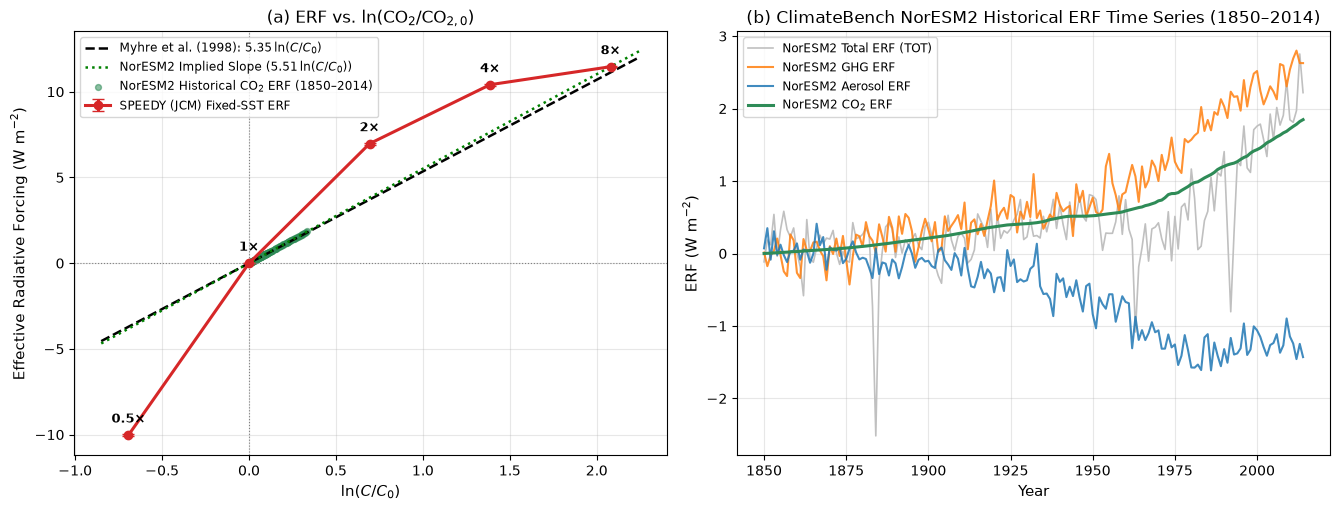


=== TASK 7: 4xCO2 FAST RESPONSE SUMMARY ===
Temperature field used:                  Near-Surface Air Temperature (`surface_flux.t0`)
Global-mean ΔT (fixed SST):              +0.344 K
Land-mean ΔT (fmask > 0.1):              +0.604 K
Control Global-mean Precipitation:       2.801 mm day⁻¹
4xCO2 Fast Global-mean ΔP:               -0.0817 mm day⁻¹ (-2.92%)
4xCO2 ERF:                               +10.410 W m⁻²
Global-mean ΔP per W m⁻² of forcing:     -0.0079 mm day⁻¹ (W m⁻²)⁻¹ (-0.28% per W m⁻²)
Latent heat change (L_v ΔP / ERF):       -0.227 W m⁻² per W m⁻²


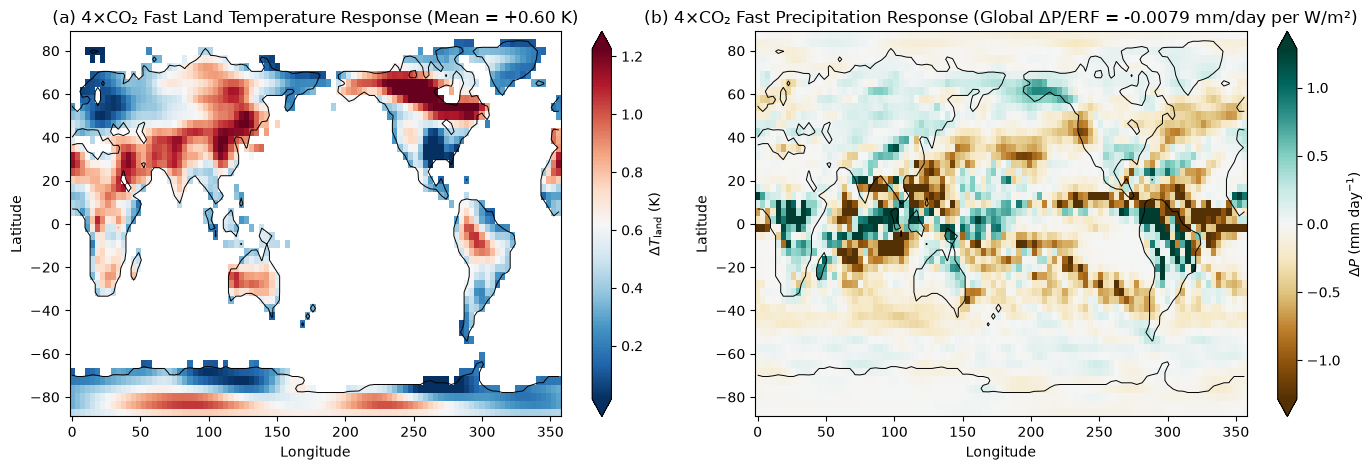

In [14]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ==============================================================================
# 1. Load (or use in-memory) the 5 Annual-Mean Datasets
# ==============================================================================
multipliers = [0.5, 1.0, 2.0, 4.0, 8.0]
if "experiments" not in globals() or len(experiments) < 5:
    experiments = {
        m: xr.open_dataset(f"co2_runs/speedy_co2_{m}x_annual.nc")
        for m in multipliers
    }

ds_0p5x = experiments[0.5]
ds_ctrl = experiments[1.0]
ds_2x   = experiments[2.0]
ds_4x   = experiments[4.0]
ds_8x   = experiments[8.0]

spinup_years = 1
analysis_years = ds_ctrl.sizes["time"] - spinup_years
c0 = 420.0  # Control CO2 (ppmv)

# ==============================================================================
# 2. Task 6: Compute ERF, Standard Errors, and Verify `ablco2`
# ==============================================================================
def get_annual_global_toa(ds, spinup_years=1):
    """
    Computes post-spinup annual-mean global-mean net downward TOA flux (W m^-2).
    """
    ds_post = ds.isel(time=slice(spinup_years, None))
    sw_top = ds_post["shortwave_rad.ftop"]
    lw_top = ds_post["longwave_rad.ftop"]
    
    # In SPEEDY, shortwave_rad.ftop is downward net SW (>0) and longwave_rad.ftop is upward OLR (>0)
    if float(lw_top.mean().values) > 0:
        toa_net = sw_top - lw_top
    else:
        toa_net = sw_top + lw_top
        
    weights = np.cos(np.deg2rad(toa_net.lat))
    global_annual = toa_net.weighted(weights).mean(dim=("lat", "lon"))
    return np.asarray(global_annual.values, dtype=float)

ratios = np.array([0.5, 1.0, 2.0, 4.0, 8.0])
ln_ratios = np.log(ratios)

toa_ctrl_ann = get_annual_global_toa(ds_ctrl, spinup_years=spinup_years)
n_ctrl = len(toa_ctrl_ann)
var_ctrl = np.var(toa_ctrl_ann, ddof=1)

erf_vals = []
erf_ses = []
ablco2_vals = []

print("=== TASK 6: EFFECTIVE RADIATIVE FORCING (ERF) SUMMARY ===")
print(f"Control Global-Mean TOA Net Flux: {np.mean(toa_ctrl_ann):+.3f} W m⁻² (interannual SD = {np.sqrt(var_ctrl):.3f} W m⁻²)\n")
print(f"{'Mult':>5} | {'CO2 (ppmv)':>10} | {'ablco2':>8} | {'ln(C/C0)':>8} | {'SPEEDY ERF (W/m²)':>18} | {'Myhre 1998 (W/m²)':>17}")
print("-" * 80)

for r in ratios:
    ds_r = experiments[r]
    abl = float(ds_r["mod_radcon.ablco2"].isel(time=slice(spinup_years, None)).mean().values)
    ablco2_vals.append(abl)
    
    if r == 1.0:
        erf, se = 0.0, 0.0
    else:
        toa_pert_ann = get_annual_global_toa(ds_r, spinup_years=spinup_years)
        n_pert = len(toa_pert_ann)
        var_pert = np.var(toa_pert_ann, ddof=1)
        erf = float(np.mean(toa_pert_ann) - np.mean(toa_ctrl_ann))
        se = float(np.sqrt(var_pert / n_pert + var_ctrl / n_ctrl))
        
    erf_vals.append(erf)
    erf_ses.append(se)
    myhre = 5.35 * np.log(r)
    print(f"{r:4.1f}x | {c0*r:10.1f} | {abl:8.4f} | {np.log(r):+8.4f} | {erf:+8.3f} ± {se:6.3f} | {myhre:+17.3f}")

erf_vals = np.array(erf_vals)
erf_ses = np.array(erf_ses)

# ==============================================================================
# 3. Task 6 Plot: SPEEDY ERF vs. Myhre (1998) and ClimateBench NorESM2 ERF
# ==============================================================================
noresm_df = pd.read_csv("inputs_NorESM2_ERF.csv")
# Map NorESM2 historical CO2 ERF (1850-2014) onto ln(C/C0) using CMIP6 historical CO2
# (1850: 284.32 ppmv -> 2014: 397.55 ppmv, ln(C_2014/C_1850) = 0.3352, Implied slope = 5.511 W/m²)
noresm_slope = noresm_df["CO2"].iloc[-1] / np.log(397.55 / 284.32)
noresm_ln_c = noresm_df["CO2"] / noresm_slope

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2))

x_line = np.linspace(-0.85, 2.25, 200)
ax1.plot(x_line, 5.35 * x_line, "k--", lw=1.8, label=r"Myhre et al. (1998): $5.35\,\ln(C/C_0)$")
ax1.plot(x_line, noresm_slope * x_line, "g:", lw=1.8, label=rf"NorESM2 Implied Slope ($5.51\,\ln(C/C_0)$)")
ax1.scatter(noresm_ln_c, noresm_df["CO2"], color="seagreen", s=18, alpha=0.55, label="NorESM2 Historical $\mathrm{CO_2}$ ERF (1850–2014)")
ax1.errorbar(ln_ratios, erf_vals, yerr=erf_ses, fmt="o-", color="tab:red", lw=2.2, capsize=4, markersize=6, label="SPEEDY (JCM) Fixed-SST ERF")

for r, x, y in zip(ratios, ln_ratios, erf_vals):
    ax1.annotate(f"{r:g}×", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontweight="bold", fontsize=9)

ax1.axhline(0, color="gray", lw=0.8, ls=":")
ax1.axvline(0, color="gray", lw=0.8, ls=":")
ax1.set_xlabel(r"$\ln(C / C_0)$", fontsize=11)
ax1.set_ylabel(r"Effective Radiative Forcing ($\mathrm{W\ m^{-2}}$)", fontsize=11)
ax1.set_title(r"(a) ERF vs. $\ln(\mathrm{CO_2 / CO_{2,0}})$", fontsize=12)
ax1.legend(loc="upper left", fontsize=8.8)
ax1.grid(True, alpha=0.3)

ax2.plot(noresm_df["year"], noresm_df["TOT"], color="silver", lw=1.2, label="NorESM2 Total ERF (TOT)")
ax2.plot(noresm_df["year"], noresm_df["GHG"], color="tab:orange", lw=1.5, alpha=0.85, label="NorESM2 GHG ERF")
ax2.plot(noresm_df["year"], noresm_df["AER"], color="tab:blue", lw=1.5, alpha=0.85, label="NorESM2 Aerosol ERF")
ax2.plot(noresm_df["year"], noresm_df["CO2"], color="seagreen", lw=2.2, label="NorESM2 $\mathrm{CO_2}$ ERF")
ax2.set_xlabel("Year", fontsize=11)
ax2.set_ylabel(r"ERF ($\mathrm{W\ m^{-2}}$)", fontsize=11)
ax2.set_title("(b) ClimateBench NorESM2 Historical ERF Time Series (1850–2014)", fontsize=12)
ax2.legend(loc="upper left", fontsize=8.8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("task6_erf_vs_co2.png", dpi=300)
plt.show()

# ==============================================================================
# 4. Task 7: Fast Responses in 4xCO2 Fixed-SST Run (Land T & Precipitation)
# ==============================================================================
t_slice = slice(spinup_years, None)

# Build land-sea mask DataArray aligned with (lat, lon) or (lon, lat)
sample_var = ds_ctrl["surface_flux.t0"].isel(time=t_slice).mean("time")
fmask_np = np.asarray(terrain.fmask)
if sample_var.dims == ("lat", "lon") and fmask_np.shape == (ds_ctrl.sizes["lon"], ds_ctrl.sizes["lat"]):
    fmask_da = xr.DataArray(fmask_np.T, coords={"lat": ds_ctrl.lat, "lon": ds_ctrl.lon}, dims=("lat", "lon"))
elif sample_var.dims == ("lon", "lat") and fmask_np.shape == (ds_ctrl.sizes["lon"], ds_ctrl.sizes["lat"]):
    fmask_da = xr.DataArray(fmask_np, coords={"lon": ds_ctrl.lon, "lat": ds_ctrl.lat}, dims=("lon", "lat"))
else:
    fmask_da = xr.DataArray(fmask_np, coords=sample_var.coords, dims=sample_var.dims)

# Check both near-surface air temperature ('surface_flux.t0') and land skin temperature ('land_model.stl_lm')
dt_air = (ds_4x["surface_flux.t0"].isel(time=t_slice).mean("time") -
          ds_ctrl["surface_flux.t0"].isel(time=t_slice).mean("time"))
dt_stl = (ds_4x["land_model.stl_lm"].isel(time=t_slice).mean("time") -
          ds_ctrl["land_model.stl_lm"].isel(time=t_slice).mean("time"))

if float(np.abs(dt_stl).max()) > 1e-4:
    dt_chosen = dt_stl
    t_label = "Land Surface Temperature (`land_model.stl_lm`)"
else:
    dt_chosen = dt_air
    t_label = "Near-Surface Air Temperature (`surface_flux.t0`)"

dt_land_only = dt_chosen.where(fmask_da > 0.1)

# Precipitation: check units of 'surface_exchange.precipitation'
p_raw_ctrl = ds_ctrl["surface_exchange.precipitation"].isel(time=t_slice).mean("time")
p_raw_4x   = ds_4x["surface_exchange.precipitation"].isel(time=t_slice).mean("time")

raw_mean = float(np.abs(p_raw_ctrl).mean())
if raw_mean < 1e-3:        # kg m^-2 s^-1 (mm/s) -> multiply by 86400
    p_factor = 86400.0
elif raw_mean < 0.1:       # g m^-2 s^-1 -> multiply by 86.4
    p_factor = 86.4
else:                      # Already in mm/day
    p_factor = 1.0

p_ctrl = p_raw_ctrl * p_factor
p_4x   = p_raw_4x * p_factor
dp_map = p_4x - p_ctrl

# Area-weighted global and land means
weights = np.cos(np.deg2rad(ds_ctrl.lat))
dt_global_mean = float(dt_chosen.weighted(weights).mean(dim=("lat", "lon")).values)
dt_land_mean   = float(dt_chosen.weighted(weights * (fmask_da > 0.1)).mean(dim=("lat", "lon")).values)

p_ctrl_global  = float(p_ctrl.weighted(weights).mean(dim=("lat", "lon")).values)
dp_global_mean = float(dp_map.weighted(weights).mean(dim=("lat", "lon")).values)
dp_pct_global  = 100.0 * dp_global_mean / p_ctrl_global

erf_4x = erf_vals[3]  # 4xCO2 ERF
dp_per_wm2 = dp_global_mean / erf_4x
dp_pct_per_wm2 = dp_pct_global / erf_4x
lv_wm2_per_wm2 = (dp_global_mean * (2.5e6 / 86400.0)) / erf_4x

print("\n=== TASK 7: 4xCO2 FAST RESPONSE SUMMARY ===")
print(f"Temperature field used:                  {t_label}")
print(f"Global-mean ΔT (fixed SST):              {dt_global_mean:+.3f} K")
print(f"Land-mean ΔT (fmask > 0.1):              {dt_land_mean:+.3f} K")
print(f"Control Global-mean Precipitation:       {p_ctrl_global:.3f} mm day⁻¹")
print(f"4xCO2 Fast Global-mean ΔP:               {dp_global_mean:+.4f} mm day⁻¹ ({dp_pct_global:+.2f}%)")
print(f"4xCO2 ERF:                               {erf_4x:+.3f} W m⁻²")
print(f"Global-mean ΔP per W m⁻² of forcing:     {dp_per_wm2:+.4f} mm day⁻¹ (W m⁻²)⁻¹ ({dp_pct_per_wm2:+.2f}% per W m⁻²)")
print(f"Latent heat change (L_v ΔP / ERF):       {lv_wm2_per_wm2:+.3f} W m⁻² per W m⁻²")

# Plot Task 7 Maps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

dt_land_only.transpose("lat", "lon").plot.pcolormesh(
    ax=ax1, cmap="RdBu_r", robust=True, cbar_kwargs={"label": r"$\Delta T_{\mathrm{land}}$ (K)"}
)
ax1.contour(ds_ctrl.lon, ds_ctrl.lat, fmask_da.transpose("lat", "lon"), levels=[0.5], colors="k", linewidths=0.7)
ax1.set_title(f"(a) 4×CO₂ Fast Land Temperature Response (Mean = {dt_land_mean:+.2f} K)")
ax1.set_xlabel("Longitude")
ax1.set_ylabel("Latitude")

dp_map.transpose("lat", "lon").plot.pcolormesh(
    ax=ax2, cmap="BrBG", robust=True, cbar_kwargs={"label": r"$\Delta P$ ($\mathrm{mm\ day^{-1}}$)"}
)
ax2.contour(ds_ctrl.lon, ds_ctrl.lat, fmask_da.transpose("lat", "lon"), levels=[0.5], colors="k", linewidths=0.7)
ax2.set_title(f"(b) 4×CO₂ Fast Precipitation Response (Global ΔP/ERF = {dp_per_wm2:+.4f} mm/day per W/m²)")
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")

plt.tight_layout()
plt.savefig("task7_fast_response_maps.png", dpi=300)
plt.show()